In [7]:
import matplotlib
# matplotlib.use("Agg")
import matplotlib.pyplot as plt
from pyclustree import clustree
import scanpy as sc

In [3]:
Acer = sc.read_h5ad("./matrix/01_Acer_transfromHY.h5ad")
Acer

AnnData object with n_obs × n_vars = 58166 × 11817
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'batch', 'leiden_res0.25', 'leiden_res0.50', 'leiden_res1.00', 'HY_barcode', 'celltype_transfrom_HY'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'batch_colors', 'celltype_transfrom_HY_colors', 'hvg', 'leiden_res0.25', 'leiden_res0.25_colors', 'leiden_res0.50', 'leiden_res0.50_colors', 'leiden_res1.00', 'leiden_res1.00_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_scVI', 'X_umap'
    varm: 'PCs'
    layers: 'counts', 'logcounts'
    obsp: 'connectivities', 'distances'

In [4]:
resolutions = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00, 1.10, 1.20]
for resolution in resolutions:
    sc.tl.leiden(
        Acer, 
        key_added=f"leiden_neo_res_{resolution:.2f}", 
        resolution=resolution, 
        flavor="leidenalg", 
        n_iterations=-1
    )

/tmp/ipykernel_108528/3058378689.py:3: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


In [5]:
resolutions = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.9]
keys = [f"leiden_neo_res_{r:.2f}" for r in resolutions]
fig = clustree(
    Acer,
    keys, # 必须按 resolution 从小到大
    title="Leiden clusters across resolutions",
    edge_weight_threshold=0.05, # 隐藏很弱的边，减少杂乱
    show_fraction=True,# 边上显示父簇流向子簇的比例
    node_size_range=(100, 800),
)
fig.savefig("figures/clustree_res.png", dpi=300, bbox_inches="tight")

In [5]:
Acer.write_h5ad("./matrix/02_Acer_reclustered.h5ad")

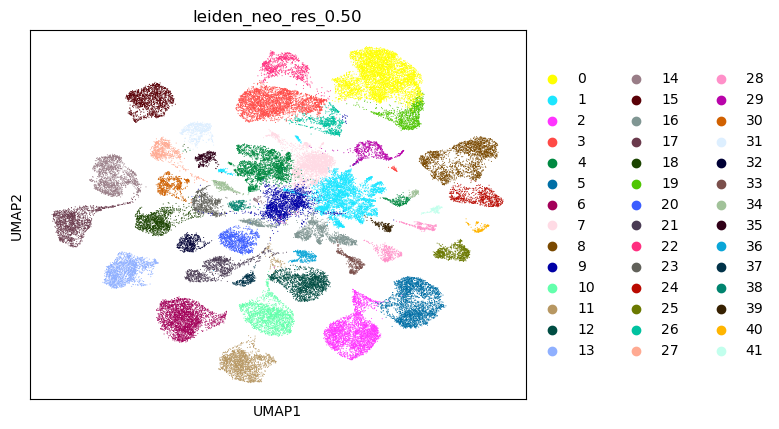

In [8]:
sc.pl.umap(Acer, color=["leiden_neo_res_0.50"])